In [137]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [138]:
df = pd.read_csv("../data/processed/real_balanced_reviews.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

Dataset shape: (120000, 3)

Columns:
['rating', 'review', 'sentiment']

Sentiment distribution:
sentiment
Negative    40000
Positive    40000
Neutral     40000
Name: count, dtype: int64


In [139]:
X = df["review"]
y = df["sentiment"]

print("Input samples:", len(X))
print("Output samples:", len(y))

Input samples: 120000
Output samples: 120000


In [140]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 96000
Testing samples: 24000


In [141]:
vectorizer = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("TF-IDF training shape:", X_train_tfidf.shape)
print("TF-IDF testing shape:", X_test_tfidf.shape)

TF-IDF training shape: (96000, 50000)
TF-IDF testing shape: (24000, 50000)


In [142]:
model = LogisticRegression(
    max_iter=1000
)

model.fit(X_train_tfidf, y_train)

print("Real sentiment model trained successfully!")

Real sentiment model trained successfully!


In [143]:
y_pred = model.predict(X_test_tfidf)

print("Predictions completed!")
print("Number of predictions:", len(y_pred))

Predictions completed!
Number of predictions: 24000


In [144]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

Model Accuracy: 0.8001666666666667
Accuracy Percentage: 80.02 %


In [145]:
print("Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Classification Report:

              precision    recall  f1-score   support

    Negative       0.81      0.80      0.81      8000
     Neutral       0.73      0.75      0.74      8000
    Positive       0.86      0.85      0.85      8000

    accuracy                           0.80     24000
   macro avg       0.80      0.80      0.80     24000
weighted avg       0.80      0.80      0.80     24000



In [146]:
print("Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Classification Report:

              precision    recall  f1-score   support

    Negative       0.81      0.80      0.81      8000
     Neutral       0.73      0.75      0.74      8000
    Positive       0.86      0.85      0.85      8000

    accuracy                           0.80     24000
   macro avg       0.80      0.80      0.80     24000
weighted avg       0.80      0.80      0.80     24000



In [147]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[6432 1259  309]
 [1231 5987  782]
 [ 315  900 6785]]


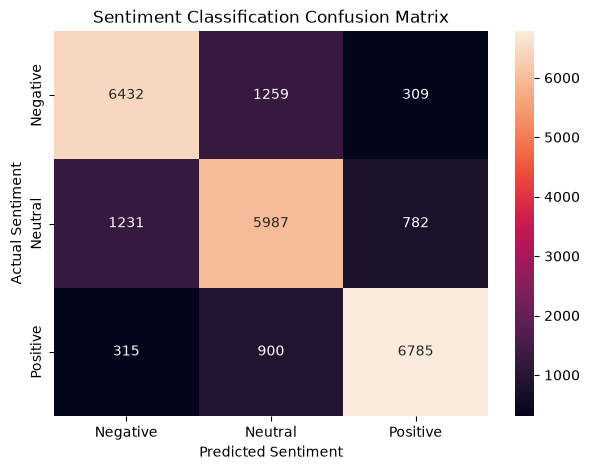

In [148]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Sentiment Classification Confusion Matrix")
plt.show()

In [149]:
new_reviews = [
    "This product is absolutely amazing and I love it",
    "The product is okay, nothing special",
    "I hate this product, it is terrible and useless"
]

new_reviews_tfidf = vectorizer.transform(new_reviews)

predictions = model.predict(new_reviews_tfidf)

for review, sentiment in zip(new_reviews, predictions):
    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("-" * 60)

Review: This product is absolutely amazing and I love it
Predicted Sentiment: Positive
------------------------------------------------------------
Review: The product is okay, nothing special
Predicted Sentiment: Neutral
------------------------------------------------------------
Review: I hate this product, it is terrible and useless
Predicted Sentiment: Negative
------------------------------------------------------------


In [150]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

Model Accuracy: 0.8001666666666667
Accuracy Percentage: 80.02 %


In [151]:
print("Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Classification Report:

              precision    recall  f1-score   support

    Negative       0.81      0.80      0.81      8000
     Neutral       0.73      0.75      0.74      8000
    Positive       0.86      0.85      0.85      8000

    accuracy                           0.80     24000
   macro avg       0.80      0.80      0.80     24000
weighted avg       0.80      0.80      0.80     24000



In [152]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[6432 1259  309]
 [1231 5987  782]
 [ 315  900 6785]]


In [153]:
import joblib

joblib.dump(model, "../data/processed/sentiment_model.pkl")
joblib.dump(vectorizer, "../data/processed/tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!
